# Goal:

Try different time stemp on of the data to see the variation of the x = [fc, B99, FWHM, B10, B20, B30, RBW, A, S] at each time stemp.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import math
import os

from rfi_pipeline import analyze_time_bins


import h5py
import xarray as xr
import pandas as pd
from scipy.signal import find_peaks, peak_widths
from astropy.stats import median_absolute_deviation as MAD
from pybaselines import Baseline, utils 


import scienceplots
plt.style.use(['science', 'no-latex'])


# Load the data

Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5


In [2]:
# DATA
filename = "EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# Create a dictionary to store the plots
dirname = filename.split('.')[0]

to_save = False  # Set to True to save the plots, False to just display them


In [4]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

datasets = {}

with h5py.File(path, 'r') as f:
    for g in groups:

        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]
        frequency = f[f"{g}/frequency"][1600:-60] / 1e6 # MHz
        time      = f[f"{g}/timestamp"][30:,0]
        integration_time = f[f"{g}/integration_time"][30:,0]
        ra = f[f"{g}/ra"][30:]
        dec = f[f"{g}/dec"][30:]
        elevation = f[f"{g}/elevation"][30:]
        azimuth = f[f"{g}/azimuth"][30:]

        ds = xr.Dataset(
            {"spectrum": (("time","frequency"), spectrum)},
            coords={"time": time, "frequency": frequency, "integration_time": integration_time, "ra": ra, "dec": dec, "elevation": elevation, "azimuth": azimuth}
        )

        datasets[g] = ds

In [5]:
# select a scan
scan = 'scan/000/P1_ND0'
# Extract scan name
scan_name = scan.replace('/', '_')

data = datasets[scan]
data

<xarray.Dataset> Size: 163MB
Dimensions:           (time: 634, frequency: 63877, integration_time: 634,
                       ra: 634, dec: 634, elevation: 634, azimuth: 634)
Coordinates:
  * time              (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09
  * frequency         (frequency) float64 511kB 1.793e+03 ... 3.498e+03
  * integration_time  (integration_time) float64 5kB 0.1158 0.1129 ... 0.1159
  * ra                (ra) float64 5kB 82.06 82.06 82.07 ... 85.21 85.22 85.22
  * dec               (dec) float64 5kB 22.68 22.68 22.68 ... 21.3 21.3 21.29
  * elevation         (elevation) float64 5kB 30.51 30.5 30.51 ... 30.51 30.51
  * azimuth           (azimuth) float64 5kB 29.42 29.42 29.42 ... 32.78 32.79
Data variables:
    spectrum          (time, frequency) float32 162MB 1.883e+11 ... 4.159e+09

In [ ]:
# define the variables
spectra = data['spectrum'].values
integration_time = data['integration_time'].values
spectrum = spectra / integration_time[:, np.newaxis]
frequency_mhz = data['frequency'].values 
time = data['time'].values
elevation = data['elevation'].values
azimuth = data['azimuth'].values



# Spectrum to dB
spectrum_db = 10*np.log10(spectrum**2)
mean_spectrum_db = np.mean(spectrum_db, axis=0)


# Time to UTC
time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)


In [ ]:
spectrum.shape

(634, 63877)

In [ ]:
list(np.arange(3,15,3))

[np.int64(3), np.int64(6), np.int64(9), np.int64(12)]

In [ ]:
# perform the anlysis on the binned data

results = analyze_time_bins(spectrum, frequency_mhz, 
                             time_bins=list(np.arange(3,30,3))
                             )
results

,time_bin,peak_index,start_index,end_index,peak_height,f_peak,fc,B99,B99_start,B99_end,...,B30_end,RBW,A,S,moment_std,snr_local,snr_integrated,local_noise_sigma,local_noise_median,n_noise_channels
0,3,1007,908,1211,3.428665e+12,1819.601059,1820.518964,7.743835,1817.144394,1824.888229,...,1825.753206,0.026703,1.646404e+14,0.704041,1.689648,60.387240,159.592958,5.635100e+10,2.578354e+10,100
1,3,7867,7742,7989,7.201840e+12,2002.782822,2002.758204,6.061554,1999.685287,2005.746841,...,2008.543222,0.026703,2.595499e+14,-0.133602,0.879410,190.737854,396.735140,3.718181e+10,1.098616e+11,100
2,3,11744,11707,11773,3.831093e+11,2106.309891,2106.203860,1.682281,2105.348587,2107.030869,...,2107.851525,0.026703,1.444506e+13,0.009061,0.486636,4.219646,18.579611,8.591275e+10,2.058789e+10,100
3,3,13154,13021,13177,9.603988e+11,2143.960953,2142.697051,3.952026,2140.489578,2144.441605,...,2144.587376,0.026703,8.793202e+13,-0.289394,1.062506,26.954199,202.210268,3.701182e+10,-3.722523e+10,69
4,3,13225,13202,13361,1.087604e+12,2145.856857,2147.224454,4.032135,2145.322800,2149.354935,...,2149.632744,0.026703,1.154928e+14,0.156671,1.087101,29.796001,256.413408,3.840253e+10,-5.663774e+10,69
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,27,13226,13201,13358,9.751655e+11,2145.883560,2147.096920,3.978729,2145.296097,2149.274826,...,2149.529032,0.026703,8.628157e+13,0.272712,1.064209,32.693996,237.168307,3.103448e+10,-3.947574e+10,70
83,27,13244,13201,13358,8.570690e+11,2146.364212,2147.096920,3.978729,2145.296097,2149.274826,...,2149.529062,0.026703,8.628157e+13,0.272712,1.064209,28.888664,237.168307,3.103448e+10,-3.947574e+10,70
84,27,13320,13201,13358,5.824726e+11,2148.393631,2147.096920,3.978729,2145.296097,2149.274826,...,2149.529130,0.026703,8.628157e+13,0.272712,1.064209,20.040558,237.168307,3.103448e+10,-3.947574e+10,70
85,27,15251,15155,15342,6.520959e+12,2199.956894,2199.907271,4.619598,2197.580338,2202.199936,...,2203.395432,0.026703,2.367784e+14,-0.086878,0.732932,125.229410,309.755117,5.126259e+10,1.013753e+11,100


In [ ]:
results['f_peak'].unique()


array([1819.60105896, 2002.78282166, 2106.30989075, 2143.96095276,
       2145.8568573 , 2146.87156677, 2199.95689392, 2362.89787292,
       2106.36329651, 2143.93424988, 2145.88356018, 2147.05848694,
       2147.32551575, 2199.90348816, 2287.32872009, 2362.68424988,
       1892.82035828, 2106.38999939, 2144.12117004, 2199.93019104,
       2287.0349884 , 2363.16490173, 1819.65446472, 2142.0917511 ,
       2142.81272888, 2143.45359802, 2144.0410614 , 2145.96366882,
       2146.95167542, 2147.37892151, 2148.74076843, 2287.67585754,
       2363.29841614, 1819.62776184, 2144.01435852, 2148.07319641,
       2199.9835968 , 2362.81776428, 1819.6811676 , 2002.80952454,
       2143.4803009 , 2148.39363098, 2148.95439148, 2362.71095276,
       2287.40882874, 2002.75611877, 2143.23997498, 2143.80073547,
       2362.7910614 , 2143.40019226, 2143.85414124, 2146.36421204,
       2362.55073547])

In [ ]:
spectrum_time = spectrum[0,:]

In [ ]:
"""
plot_peak_height_vs_time.py
============================
Visualise how peak_height evolves across time bins for each matched RFI source.

One line per unique RFI source (grouped by rounded peak frequency).
Y-axis is log-scale (peak_height spans orders of magnitude).
X-axis is ordinal — the discrete time_bin values.

Usage
-----
    from plot_peak_height_vs_time import plot_peak_height_vs_time
    fig = plot_peak_height_vs_time(results)           # results = DataFrame from analyze_time_bins
    fig.savefig("peak_height_vs_time.pdf", bbox_inches="tight")

    # Adjust grouping resolution (default 5 MHz):
    fig = plot_peak_height_vs_time(results, freq_round=10)
"""


import matplotlib.ticker as mticker

# ── Categorical palette (identity job, fixed order) ──────────────────────────
# Blue, orange, aqua, yellow, magenta, green, violet, red
_CAT = [
    "#2a78d6",  # slot 1 – blue
    "#eb6834",  # slot 2 – orange
    "#1baf7a",  # slot 3 – aqua
    "#eda100",  # slot 4 – yellow
    "#e87ba4",  # slot 5 – magenta
    "#008300",  # slot 6 – green
    "#6250d6",  # slot 7 – violet
    "#e34948",  # slot 8 – red
]

# Chart chrome
_SURFACE   = "#fcfcfb"
_INK_PRI   = "#0b0b0b"
_INK_SEC   = "#52514e"
_INK_MUTED = "#898781"
_GRID      = "#e1e0d9"
_BASELINE  = "#c3c2b7"


def plot_peak_height_vs_time(
    results: pd.DataFrame,
    column_to_plot: str = "peak_height",
    freq_round: float = 5.0,
    figsize: tuple = (9, 5.5),
    title: str = "Peak height across time bins",
) -> plt.Figure:
    """
    Line chart: peak_height (log scale) vs time_bin, one line per RFI source.

    Parameters
    ----------
    results    : DataFrame from analyze_time_bins (must have time_bin,
                 f_peak, peak_height columns).
    freq_round : MHz rounding used to group peaks into the same "source".
                 Increase if peaks drift more than 1–2 channels between bins.
    figsize    : Figure size in inches.
    title      : Chart title.

    Returns
    -------
    fig : matplotlib Figure
    """
    df = results[["time_bin", "f_peak", "peak_height"]].copy()

    # ── Group by rounded frequency ─────────────────────────────────────────
    df["f_group"] = (df["f_peak"] / freq_round).round().astype(int) * freq_round

    # Within each (time_bin, f_group) keep the tallest detection
    grouped = (
        df.groupby(["f_group", "time_bin"], as_index=False)["peak_height"]
        .max()
    )

    sources = sorted(grouped["f_group"].unique())
    time_vals = sorted(grouped["time_bin"].unique())
    n_src = len(sources)

    # ── Decide rendering strategy ──────────────────────────────────────────
    # ≤ 8 sources: categorical colour, one line each
    # > 8 sources: top-8 by max peak_height get colour; rest → "Other" (gray)
    max_h = grouped.groupby("f_group")["peak_height"].max().sort_values(ascending=False)

    if n_src <= 8:
        labelled = list(max_h.index)
        others   = []
    else:
        labelled = list(max_h.index[:8])
        others   = list(max_h.index[8:])

    # ── Figure ─────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=figsize, facecolor=_SURFACE)
    ax.set_facecolor(_SURFACE)

    # "Other" group: aggregate into a single mean line drawn first (behind)
    if others:
        other_data = (
            grouped[grouped["f_group"].isin(others)]
            .groupby("time_bin", as_index=False)["peak_height"]
            .mean()
        )
        ax.plot(
            other_data["time_bin"], other_data["peak_height"],
            color=_INK_MUTED, lw=1.5, ls="--",
            marker="o", markersize=5, markeredgewidth=0,
            label="Other (mean)",
            zorder=2,
        )

    # Named sources
    for i, src in enumerate(labelled):
        sub = grouped[grouped["f_group"] == src].sort_values("time_bin")
        color = _CAT[i % len(_CAT)]

        ax.plot(
            sub["time_bin"], sub["peak_height"],
            color=color, lw=2,
            marker="o", markersize=7, markeredgewidth=0,
            label=f"{src:.0f} MHz",
            zorder=3,
        )

        # Direct label at the last time bin
        last = sub.iloc[-1]
        ax.text(
            last["time_bin"] + (time_vals[-1] - time_vals[0]) * 0.01,
            last["peak_height"],
            f"{src:.0f} MHz",
            fontsize=7.5, color=color,
            va="center", ha="left",
        )

    # ── Axes ───────────────────────────────────────────────────────────────
    ax.set_yscale("log")
    ax.set_xticks(time_vals)
    ax.set_xticklabels([str(t) for t in time_vals],
                       fontsize=9, color=_INK_SEC)
    ax.yaxis.set_major_formatter(mticker.LogFormatterSciNotation())
    ax.tick_params(axis="both", length=0, colors=_INK_MUTED, labelsize=8)

    ax.set_xlabel("Time bin  (index)", fontsize=9, color=_INK_SEC, labelpad=6)
    ax.set_ylabel("Peak height  (linear power)", fontsize=9, color=_INK_SEC, labelpad=6)
    ax.set_title(title, fontsize=12, color=_INK_PRI, loc="left",
                 fontweight="semibold", pad=10)

    # X-axis range: add right margin so direct labels fit
    x_pad = (time_vals[-1] - time_vals[0]) * 0.18 if len(time_vals) > 1 else 1
    ax.set_xlim(time_vals[0] - x_pad * 0.2, time_vals[-1] + x_pad)

    # Grid
    ax.grid(axis="y", color=_GRID, lw=0.6, zorder=1)
    ax.set_axisbelow(True)

    # Spines
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_color(_BASELINE)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_color(_BASELINE)
    ax.spines["bottom"].set_linewidth(0.8)

    # ── Legend (only when ≤ 4 series, or fold into "Other" label) ─────────
    if n_src <= 4:
        ax.legend(
            frameon=False, fontsize=8, labelcolor=_INK_SEC,
            loc="upper left", ncol=1,
        )
    elif others:
        # Show only the "Other" entry so the legend stays minimal
        handles, lbs = ax.get_legend_handles_labels()
        other_h = [(h, l) for h, l in zip(handles, lbs) if l.startswith("Other")]
        if other_h:
            ax.legend(*zip(*other_h), frameon=False, fontsize=8,
                      labelcolor=_INK_MUTED, loc="upper left")

    # Footnote
    fig.text(0.01, 0.01,
             f"Peak matched by rounding f_peak to nearest {freq_round:.0f} MHz.  "
             "Y-axis: log scale.  Multiple detections per bin → tallest kept.",
             fontsize=7, color=_INK_MUTED)

    fig.tight_layout(rect=[0, 0.04, 1, 1])
    return fig


# # ── Quick demo (mirrors the real data structure) ─────────────────────────────
# if __name__ == "__main__":
#     import io, textwrap

#     raw = textwrap.dedent("""\
#         time_bin,f_peak,peak_height
#         2,882.5,4.12e11
#         2,925.1,7.03e12
#         2,1200.3,2.88e11
#         2,1545.0,9.10e11
#         2,2141.2,3.40e11
#         5,882.4,3.95e11
#         5,925.0,6.80e12
#         5,1200.1,3.01e11
#         5,1545.2,8.75e11
#         10,882.6,4.05e11
#         10,925.3,7.20e12
#         10,1200.0,2.70e11
#         10,1544.9,9.40e11
#     """)
#     demo = pd.read_csv(io.StringIO(raw))

#     fig = plot_peak_height_vs_time(demo, freq_round=5,
#                                    title="Peak height vs time bin — demo")
    # out = "/tmp/claude-0/-home-claude/76e98edf-72e2-56e0-b067-e620e8f3bccd/scratchpad/peak_height_demo.png"
    # # fig.savefig(out, dpi=150, bbox_inches="tight", facecolor=_SURFACE)
    # # print(f"Saved {out}")
    # # plt.show()

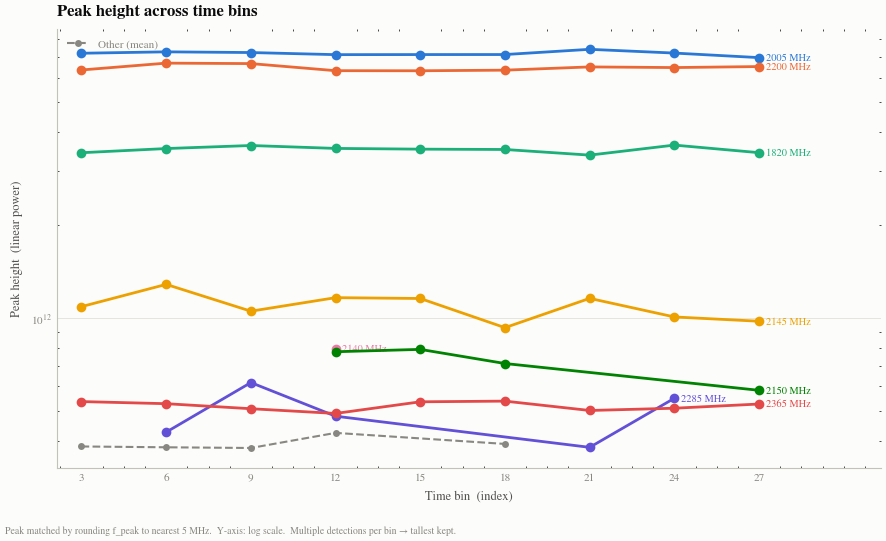

In [ ]:
fig = plot_peak_height_vs_time(results, freq_round=5)


In [ ]:
"""
plot_peak_height_vs_time.py
============================
Visualise how any RFI metric evolves across any grouping variable for each
matched RFI source.

One line per unique RFI source (grouped by rounded peak frequency).
Y-axis defaults to log-scale when the column spans > 1 order of magnitude.
X-axis is ordinal — the discrete x_col values (e.g. time_bin).

Usage
-----
    from plot_peak_height_vs_time import plot_rfi_metric

    # Default: peak_height vs time_bin
    fig = plot_rfi_metric(results)

    # Any metric vs time_bin:
    fig = plot_rfi_metric(results, y_col="B99",  title="B₉₉ vs time bin")
    fig = plot_rfi_metric(results, y_col="A",    title="Integrated power vs time bin")
    fig = plot_rfi_metric(results, y_col="S",    log_scale=False)

    # Change x-axis or grouping column:
    fig = plot_rfi_metric(results, x_col="time_bin", y_col="fc",
                          group_col="f_peak", freq_round=5)

    fig.savefig("rfi_metric.pdf", bbox_inches="tight")
"""



def plot_rfi_metric(
    results: pd.DataFrame,
    y_col: str = "peak_height",
    x_col: str = "time_bin",
    group_col: str = "f_peak",
    freq_round: float = 5.0,
    log_scale: bool | None = None,
    agg: str = "max",
    y_label: str | None = None,
    x_label: str | None = None,
    figsize: tuple = (9, 5.5),
    title: str | None = None,
) -> plt.Figure:
    """
    Line chart: any RFI metric (y_col) vs any grouping axis (x_col),
    one line per matched RFI source (grouped by group_col).

    Parameters
    ----------
    results    : DataFrame from analyze_time_bins.
    y_col      : Column to plot on the y-axis.  Default ``"peak_height"``.
    x_col      : Column to use for the x-axis.  Default ``"time_bin"``.
    group_col  : Column used to identify RFI sources across x values.
                 Default ``"f_peak"`` — peaks are rounded to ``freq_round`` MHz
                 before grouping.  Pass ``None`` to disable rounding (the raw
                 values in group_col are used as-is as group keys).
    freq_round : MHz rounding applied to group_col when group_col is a
                 frequency column.  Ignored when group_col is ``None``.
                 Default 5 MHz.
    log_scale  : Force y-axis to log (True) or linear (False) scale.
                 Default ``None`` → auto: log when the y range spans > 1 decade.
    agg        : Aggregation applied when multiple rows share the same
                 (group, x) combination.  ``"max"`` (default) keeps the tallest
                 peak; ``"mean"`` averages them.
    y_label    : Y-axis label.  Default: ``y_col``.
    x_label    : X-axis label.  Default: ``x_col``.
    figsize    : Figure size in inches.
    title      : Chart title.  Default: ``"{y_col} across {x_col}"``.

    Returns
    -------
    fig : matplotlib Figure

    Examples
    --------
    >>> fig = plot_rfi_metric(results)                         # peak_height vs time_bin
    >>> fig = plot_rfi_metric(results, y_col="B99")            # B99 vs time_bin
    >>> fig = plot_rfi_metric(results, y_col="A",  agg="mean") # mean power vs time_bin
    >>> fig = plot_rfi_metric(results, y_col="S",  log_scale=False)  # skewness (can be ±)
    >>> fig = plot_rfi_metric(results, y_col="fc", group_col=None)   # centroid, no rounding
    """
    needed = [c for c in [x_col, y_col, group_col] if c is not None]
    missing = [c for c in needed if c not in results.columns]
    if missing:
        raise ValueError(f"Column(s) not found in results: {missing}")

    df = results[needed].copy()

    # ── Group by rounded frequency ─────────────────────────────────────────
    if group_col is not None:
        df["_group"] = (
            (df[group_col] / freq_round).round().astype(int) * freq_round
        )
    else:
        df["_group"] = df[group_col] if group_col else df.index

    agg_fn = "max" if agg == "max" else "mean"
    grouped = (
        df.groupby(["_group", x_col], as_index=False)[y_col]
        .agg(agg_fn)
    )

    sources   = sorted(grouped["_group"].unique())
    x_vals    = sorted(grouped[x_col].unique())
    n_src     = len(sources)

    # ── Auto log-scale ─────────────────────────────────────────────────────
    if log_scale is None:
        vals = grouped[y_col].dropna()
        pos  = vals[vals > 0]
        log_scale = (
            len(pos) == len(vals) and
            pos.max() / pos.min() > 10
        ) if len(pos) > 1 else False

    # ── Decide rendering strategy ──────────────────────────────────────────
    max_y = grouped.groupby("_group")[y_col].max().sort_values(ascending=False)

    if n_src <= 8:
        labelled = list(max_y.index)
        others   = []
    else:
        labelled = list(max_y.index[:8])
        others   = list(max_y.index[8:])

    # ── Figure ─────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=figsize, facecolor=_SURFACE)
    ax.set_facecolor(_SURFACE)

    # "Other" group: mean line drawn behind coloured series
    if others:
        other_data = (
            grouped[grouped["_group"].isin(others)]
            .groupby(x_col, as_index=False)[y_col]
            .mean()
        )
        ax.plot(
            other_data[x_col], other_data[y_col],
            color=_INK_MUTED, lw=1.5, ls="--",
            marker="o", markersize=5, markeredgewidth=0,
            label="Other (mean)",
            zorder=2,
        )

    # Named sources
    x_span = (x_vals[-1] - x_vals[0]) if len(x_vals) > 1 else 1
    for i, src in enumerate(labelled):
        sub   = grouped[grouped["_group"] == src].sort_values(x_col)
        color = _CAT[i % len(_CAT)]

        ax.plot(
            sub[x_col], sub[y_col],
            color=color, lw=2,
            marker="o", markersize=7, markeredgewidth=0,
            label=f"{src:.0f} MHz",
            zorder=3,
        )

        # Direct label at the last x value
        last = sub.dropna(subset=[y_col]).iloc[-1]
        ax.text(
            last[x_col] + x_span * 0.01,
            last[y_col],
            f"{src:.0f} MHz",
            fontsize=7.5, color=color,
            va="center", ha="left",
        )

    # ── Axes ───────────────────────────────────────────────────────────────
    if log_scale:
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(mticker.LogFormatterSciNotation())
    else:
        ax.yaxis.set_major_formatter(mticker.ScalarFormatter(useMathText=True))
        ax.ticklabel_format(style="sci", axis="y", scilimits=(-2, 4))

    ax.set_xticks(x_vals)
    ax.set_xticklabels([str(v) for v in x_vals], fontsize=9, color=_INK_SEC)
    ax.tick_params(axis="both", length=0, colors=_INK_MUTED, labelsize=8)

    ax.set_xlabel(x_label or x_col, fontsize=9, color=_INK_SEC, labelpad=6)
    ax.set_ylabel(y_label or y_col, fontsize=9, color=_INK_SEC, labelpad=6)
    ax.set_title(
        title or f"{y_col} across {x_col}",
        fontsize=12, color=_INK_PRI, loc="left",
        fontweight="semibold", pad=10,
    )

    # X-axis right margin for direct labels
    x_pad = x_span * 0.18
    ax.set_xlim(x_vals[0] - x_pad * 0.2, x_vals[-1] + x_pad)

    # Grid
    ax.grid(axis="y", color=_GRID, lw=0.6, zorder=1)
    ax.set_axisbelow(True)

    # Spines
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_color(_BASELINE)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_color(_BASELINE)
    ax.spines["bottom"].set_linewidth(0.8)

    # ── Legend ────────────────────────────────────────────────────────────
    if n_src <= 4:
        ax.legend(
            frameon=False, fontsize=8, labelcolor=_INK_SEC,
            loc="upper left", ncol=1,
        )
    elif others:
        handles, lbs = ax.get_legend_handles_labels()
        other_h = [(h, l) for h, l in zip(handles, lbs) if l.startswith("Other")]
        if other_h:
            ax.legend(*zip(*other_h), frameon=False, fontsize=8,
                      labelcolor=_INK_MUTED, loc="upper left")

    # Footnote
    round_note = (
        f"Peaks matched by rounding {group_col} to nearest {freq_round:.0f} MHz.  "
        if group_col is not None else ""
    )
    scale_note = "Y-axis: log scale." if log_scale else "Y-axis: linear scale."
    agg_note   = f"  Multiple detections per bin → {agg} kept."
    fig.text(0.01, 0.01,
             round_note + scale_note + agg_note,
             fontsize=7, color=_INK_MUTED)

    fig.tight_layout(rect=[0, 0.04, 1, 1])
    return fig


# Backward-compatible alias
def plot_peak_height_vs_time(results, freq_round=5.0, figsize=(9, 5.5),
                              title="Peak height across time bins"):
    """Alias for plot_rfi_metric with y_col='peak_height'. Kept for compatibility."""
    return plot_rfi_metric(results, y_col="peak_height", freq_round=freq_round,
                           figsize=figsize, title=title)


# # ── Quick demo (mirrors the real data structure) ─────────────────────────────
# if __name__ == "__main__":
#     import io, textwrap

#     raw = textwrap.dedent("""\
#         time_bin,f_peak,peak_height,B99,A,S
#         2,882.5,4.12e11,2.1,3.5e13,-0.12
#         2,925.1,7.03e12,3.4,5.1e14,0.08
#         2,1200.3,2.88e11,1.8,2.2e13,-0.05
#         2,1545.0,9.10e11,2.8,7.8e13,0.21
#         2,2141.2,3.40e11,1.5,2.9e13,-0.31
#         5,882.4,3.95e11,2.0,3.3e13,-0.10
#         5,925.0,6.80e12,3.3,4.9e14,0.11
#         5,1200.1,3.01e11,1.9,2.4e13,-0.07
#         5,1545.2,8.75e11,2.7,7.5e13,0.18
#         10,882.6,4.05e11,2.2,3.4e13,-0.14
#         10,925.3,7.20e12,3.5,5.3e14,0.09
#         10,1200.0,2.70e11,1.7,2.1e13,-0.06
#         10,1544.9,9.40e11,2.9,8.0e13,0.22
#     """)
#     demo = pd.read_csv(io.StringIO(raw))

#     scratchpad = "/tmp/claude-0/-home-claude/76e98edf-72e2-56e0-b067-e620e8f3bccd/scratchpad"

#     fig = plot_rfi_metric(demo, title="Peak height vs time bin — demo")
#     fig.savefig(f"{scratchpad}/peak_height_demo.png", dpi=150,
#                 bbox_inches="tight", facecolor=_SURFACE)
#     print("Saved peak_height_demo.png")

#     fig2 = plot_rfi_metric(demo, y_col="B99",
#                            y_label="B99 bandwidth (MHz)",
#                            title="B99 occupied bandwidth vs time bin — demo")
#     fig2.savefig(f"{scratchpad}/b99_demo.png", dpi=150,
#                  bbox_inches="tight", facecolor=_SURFACE)
#     print("Saved b99_demo.png")

#     fig3 = plot_rfi_metric(demo, y_col="S", log_scale=False,
#                            y_label="Skewness (gamma_1)",
#                            title="Moment skewness vs time bin — demo")
#     fig3.savefig(f"{scratchpad}/skewness_demo.png", dpi=150,
#                  bbox_inches="tight", facecolor=_SURFACE)
#     print("Saved skewness_demo.png")

#     plt.show()

In [ ]:
results.columns

Index(['time_bin', 'peak_index', 'start_index', 'end_index', 'peak_height',
       'f_peak', 'fc', 'B99', 'B99_start', 'B99_end', 'B3', 'B3_start',
       'B3_end', 'B10', 'B10_start', 'B10_end', 'B20', 'B20_start', 'B20_end',
       'B30', 'B30_start', 'B30_end', 'RBW', 'A', 'S', 'moment_std',
       'snr_local', 'snr_integrated', 'local_noise_sigma',
       'local_noise_median', 'n_noise_channels'],
      dtype='str')

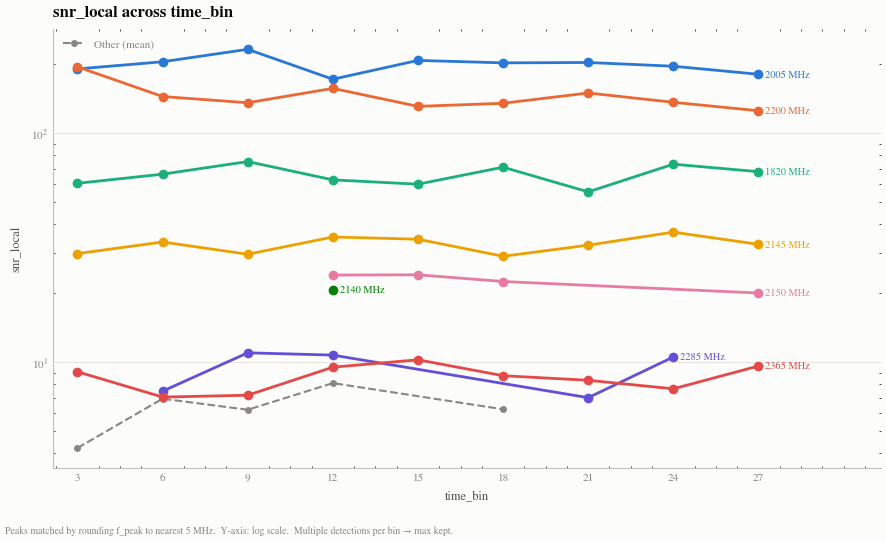

In [ ]:
fig = plot_rfi_metric(results, y_col="snr_local")

/tmp/ipykernel_2858053/3626227336.py:230: UserWarning: Glyph 8329 (\N{SUBSCRIPT NINE}) missing from font(s) STIXGeneral.
  fig.tight_layout(rect=[0, 0.04, 1, 1])
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: Glyph 8329 (\N{SUBSCRIPT NINE}) missing from font(s) STIXGeneral.
  func(*args, **kwargs)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8329 (\N{SUBSCRIPT NINE}) missing from font(s) STIXGeneral.
  fig.canvas.print_figure(bytes_io, **kw)


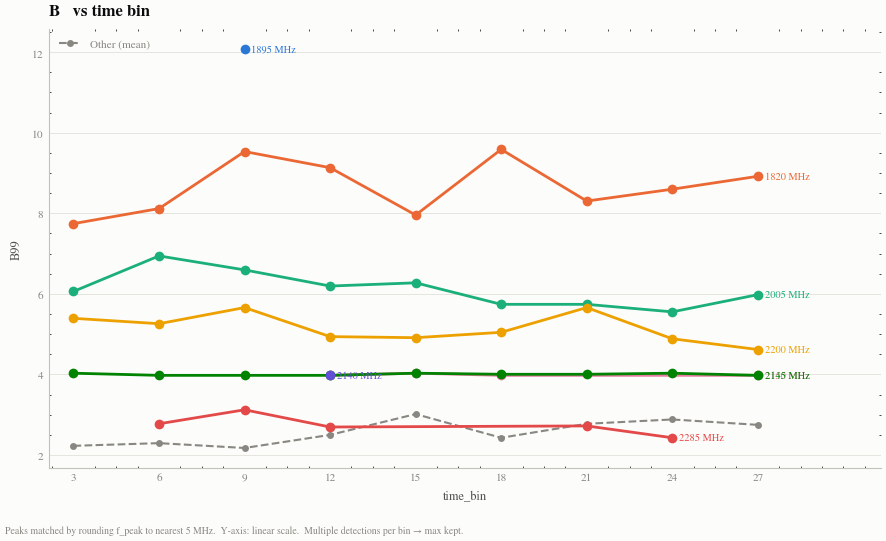

In [ ]:
fig = plot_rfi_metric(results, y_col="B99",  title="B₉₉ vs time bin")

In [ ]:
import logging


def assign_peak_groups(
    df,
    frequency_column,
    tolerance_mhz=2.0,
):
    """
    Group detected RFI peaks across time bins by frequency proximity.

    Parameters
    ----------
    df : pandas.DataFrame
        Input dataframe containing detected RFI peaks.

    frequency_column : str
        Column containing the measured peak frequency in MHz.

    tolerance_mhz : float, optional
        Maximum frequency separation, in MHz, for two detections to be
        considered part of the same peak group. Default is 2 MHz.

    Returns
    -------
    pandas.DataFrame
        Copy of the input dataframe with two additional columns:

        peak_group
            Integer group identifier.

        peak_reference_MHz
            Representative frequency of the group, calculated as the median
            frequency of all detections assigned to that group.

    Logic
    -----
    Frequencies are sorted and assigned sequentially to groups. A new
    frequency is assigned to the current group if its distance from the
    group's running median is no greater than tolerance_mhz. Otherwise,
    a new group is started.

    Notes
    -----
    This method is appropriate when distinct RFI features are separated by
    more than the chosen matching tolerance. For strongly drifting or
    overlapping signals, a time-frequency tracking algorithm should be used
    instead.
    """
    if frequency_column not in df.columns:
        raise ValueError(
            f"Column '{frequency_column}' not found in dataframe."
        )

    result = df.copy()

    valid = result[frequency_column].notna()

    frequencies = np.sort(
        result.loc[valid, frequency_column].unique()
    )

    groups = []
    current_group = []

    for freq in frequencies:

        if not current_group:
            current_group = [freq]
            continue

        reference = np.median(current_group)

        if abs(freq - reference) <= tolerance_mhz:
            current_group.append(freq)

        else:
            groups.append(current_group)
            current_group = [freq]

    if current_group:
        groups.append(current_group)

    mapping = {}

    for group_id, group_freqs in enumerate(groups):

        reference = np.median(group_freqs)

        for freq in group_freqs:
            mapping[freq] = (group_id, reference)

    result["peak_group"] = np.nan
    result["peak_reference_MHz"] = np.nan

    for index in result.index[valid]:

        freq = result.at[index, frequency_column]

        group_id, reference = mapping[freq]

        result.at[index, "peak_group"] = group_id
        result.at[index, "peak_reference_MHz"] = reference

    logging.info(
        "Assigned %d peak-frequency groups using %.3f MHz tolerance.",
        len(groups),
        tolerance_mhz,
    )

    return result


def convergence_statistics(
    df,
    column_name,
    bin_column="time_bin_s",
    threshold_percent=5.0,
    consecutive=3,
    statistic="median",
):
    """
    Compute convergence statistics for a selected DataFrame column as a
    function of time-bin size.

    Parameters
    ----------
    df : pandas.DataFrame
        Input DataFrame containing measurements at different time-bin sizes.

    column_name : str
        Name of the feature column to analyse, for example:
        'B99', 'FWHM', 'B10', 'peak_height', or 'f_center'.

    bin_column : str, optional
        Name of the column containing the time-bin duration in seconds.
        Default is 'time_bin_s'.

    threshold_percent : float, optional
        Maximum allowed percentage change between successive time-bin sizes
        for the measurement to be considered stable. Default is 5%.

    consecutive : int, optional
        Number of consecutive stable transitions required before declaring
        convergence. Default is 3.

    statistic : {'median', 'mean'}, optional
        Summary statistic used when multiple measurements exist for the same
        time-bin size. Median is recommended because it is more robust to
        outliers. Default is 'median'.

    Returns
    -------
    convergence_df : pandas.DataFrame
        Table containing, for each time-bin size:
        - representative feature value
        - absolute change
        - fractional change
        - percentage change
        - stability flag

    convergence_bin : float or None
        Smallest time-bin size at the beginning of the first sequence that
        satisfies the convergence criterion. Returns None if no convergence
        is found.

    Notes
    -----
    The convergence statistic is

        delta_i = |x_i - x_(i-1)| / |x_(i-1)|

    and the percentage change is

        D_i = 100 * delta_i.

    Convergence is declared when D_i remains below threshold_percent
    for consecutive successive transitions.
    """

    required_columns = {bin_column, column_name}

    missing = required_columns - set(df.columns)
    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    data = df[[bin_column, column_name]].copy()

    data = data.replace([np.inf, -np.inf], np.nan)
    data = data.dropna(subset=[bin_column, column_name])

    if data.empty:
        raise ValueError(
            f"No valid data available for column '{column_name}'."
        )

    if statistic == "median":
        grouped = (
            data.groupby(bin_column, as_index=False)[column_name]
            .median()
        )

    elif statistic == "mean":
        grouped = (
            data.groupby(bin_column, as_index=False)[column_name]
            .mean()
        )

    else:
        raise ValueError(
            "statistic must be either 'median' or 'mean'."
        )

    grouped = grouped.sort_values(bin_column).reset_index(drop=True)

    values = grouped[column_name].to_numpy(dtype=float)

    absolute_change = np.full(len(values), np.nan)
    fractional_change = np.full(len(values), np.nan)

    for i in range(1, len(values)):

        previous = values[i - 1]
        current = values[i]

        absolute_change[i] = abs(current - previous)

        if np.isfinite(previous) and previous != 0:
            fractional_change[i] = (
                absolute_change[i] / abs(previous)
            )

    percent_change = 100.0 * fractional_change

    stable = percent_change < threshold_percent

    grouped["absolute_change"] = absolute_change
    grouped["fractional_change"] = fractional_change
    grouped["percent_change"] = percent_change
    grouped["stable"] = stable

    convergence_bin = None

    for i in range(1, len(grouped) - consecutive + 1):

        stability_window = stable[i:i + consecutive]

        if np.all(stability_window):

            convergence_bin = grouped.loc[
                i - 1, bin_column
            ]

            break

    logging.info(
        "Convergence analysis for '%s': convergence bin = %s",
        column_name,
        convergence_bin,
    )

    return grouped, convergence_bin


In [ ]:
peak_df = assign_peak_groups(
    results,
    frequency_column="f_peak",
    tolerance_mhz=2.0)


peak_df.head(10)

,time_bin,peak_index,start_index,end_index,peak_height,f_peak,fc,B99,B99_start,B99_end,...,S,moment_std,snr_local,snr_integrated,local_noise_sigma,local_noise_median,n_noise_channels,f_group,peak_group,peak_reference_MHz
0,3,1007,908,1211,3.428665e+12,1819.601059,1820.518964,7.743835,1817.144394,1824.888229,...,0.704041,1.689648,60.387240,159.592958,5.635100e+10,2.578354e+10,100,1819.6,0.0,1819.641113
1,3,7867,7742,7989,7.201840e+12,2002.782822,2002.758204,6.061554,1999.685287,2005.746841,...,-0.133602,0.879410,190.737854,396.735140,3.718181e+10,1.098616e+11,100,2002.8,2.0,2002.782822
2,3,11744,11707,11773,3.831093e+11,2106.309891,2106.203860,1.682281,2105.348587,2107.030869,...,0.009061,0.486636,4.219646,18.579611,8.591275e+10,2.058789e+10,100,2106.3,3.0,2106.363297
3,3,13154,13021,13177,9.603988e+11,2143.960953,2142.697051,3.952026,2140.489578,2144.441605,...,-0.289394,1.062506,26.954199,202.210268,3.701182e+10,-3.722523e+10,69,2144.0,4.0,2143.800735
4,3,13225,13202,13361,1.087604e+12,2145.856857,2147.224454,4.032135,2145.322800,2149.354935,...,0.156671,1.087101,29.796001,256.413408,3.840253e+10,-5.663774e+10,69,2145.9,5.0,2147.058487
5,3,13263,13202,13361,1.021014e+12,2146.871567,2147.224454,4.032135,2145.322800,2149.354935,...,0.156671,1.087101,28.062010,256.413408,3.840253e+10,-5.663774e+10,69,2146.9,5.0,2147.058487
6,3,15251,15147,15368,6.356505e+12,2199.956894,2199.938000,5.393982,2197.393417,2202.787399,...,0.263308,0.811328,194.684576,462.990806,3.222495e+10,8.280461e+10,100,2200.0,6.0,2199.943542
7,3,21353,21292,21399,5.355561e+11,2362.897873,2362.782850,2.777100,2361.295700,2364.072800,...,-0.155849,0.696758,9.077774,45.656286,5.290023e+10,5.533978e+10,100,2362.9,8.0,2362.804413
8,6,1007,899,1219,3.537067e+12,1819.601059,1820.527405,8.117676,1816.930771,1825.048447,...,0.675733,1.748765,66.200818,170.827168,5.315353e+10,1.825918e+10,100,1819.6,0.0,1819.641113
9,6,7867,7732,8012,7.277759e+12,2002.782822,2002.778317,6.942749,1999.418259,2006.361008,...,0.152899,0.986764,204.975839,406.077783,3.500939e+10,1.016791e+11,100,2002.8,2.0,2002.782822


In [ ]:

results_convergence_statistics, convergence_bin = convergence_statistics(
    peak_df,
    column_name="B99",
    bin_column="time_bin",
    threshold_percent=5,
    consecutive=3,
)

results_convergence_statistics


,time_bin,B99,absolute_change,fractional_change,percent_change,stable
0,3,4.032135,NaN,NaN,NaN,False
1,6,3.978729,0.053406,0.013245,1.324503,True
2,9,3.898621,0.080109,0.020134,2.013423,True
3,12,3.978729,0.080109,0.020548,2.054795,True
4,15,4.032135,0.053406,0.013423,1.342282,True
5,18,3.992081,0.040054,0.009934,0.993377,True
6,21,4.005432,0.013351,0.003344,0.334448,True
7,24,4.032135,0.026703,0.006667,0.666667,True
8,27,3.978729,0.053406,0.013245,1.324503,True


In [ ]:

# First, match peaks across bins by rounding f_peak to nearest 0.1 MHz
results['f_group'] = results['f_peak'].round(1)

# Pivot: one group = one matched RFI source
grouped = results.groupby('f_group')

summary = grouped.agg(
    n_detections = ('time_bin', 'count'),
    fc_mean      = ('fc',   'mean'),
    fc_cv        = ('fc',   lambda x: x.std() / x.mean() if x.mean() != 0 else np.nan),
    B99_mean     = ('B99',  'mean'),
    B99_cv       = ('B99',  lambda x: x.std() / x.mean() if x.mean() != 0 else np.nan),
    FWHM_mean      = ('FWHM',   'mean'),
    FWHM_cv        = ('FWHM',   lambda x: x.std() / x.mean() if x.mean() != 0 else np.nan),
    A_mean       = ('A',    'mean'),
    A_cv         = ('A',    lambda x: x.std() / x.mean() if x.mean() != 0 else np.nan),
    S_mean       = ('S',    'mean'),
    S_std        = ('S',    'std'),
).reset_index()

print(summary.sort_values('B99_mean', ascending=False))

    f_group  n_detections      fc_mean     fc_cv   B99_mean    B99_cv  \
2    1892.8             1  1892.139942       NaN  12.069702       NaN   
1    1819.7             2  1820.579778  0.000007   9.359360  0.034296   
0    1819.6             7  1820.544479  0.000010   8.453369  0.073038   
3    2002.8             9  2002.754217  0.000014   6.120894  0.072206   
27   2199.9             6  2199.916784  0.000006   5.242666  0.066462   
28   2200.0             3  2199.912316  0.000011   4.975637  0.078570   
8    2143.2             1  2142.577248       NaN   4.032135       NaN   
18   2146.9             1  2147.224454       NaN   4.032135       NaN   
23   2148.1             1  2147.164791       NaN   4.032135       NaN   
11   2143.8             1  2142.577248       NaN   4.032135       NaN   
19   2147.0             2  2147.173903  0.000006   4.005432  0.009428   
10   2143.5             2  2142.638964  0.000009   3.992081  0.004730   
13   2144.0             4  2142.654483  0.000014   

# We selected the time bin to be 6 seconds

In [ ]:
results_touse_6s = results[results['time_bin'] == 6]
results_touse_6s

,time_bin,peak_index,start_index,end_index,peak_height,f_peak,fc,B99,B99_start,B99_end,...,RBW,A,S,moment_std,snr_local,snr_integrated,local_noise_sigma,local_noise_median,n_noise_channels,f_group
8,6,1007,899,1219,3.537067e+12,1819.601059,1820.527405,8.117676,1816.930771,1825.048447,...,0.026703,1.685440e+14,0.675733,1.748765,66.200818,170.827168,5.315353e+10,1.825918e+10,100,1819.6
9,6,7867,7732,8012,7.277759e+12,2002.782822,2002.778317,6.942749,1999.418259,2006.361008,...,0.026703,2.668844e+14,0.152899,0.986764,204.975839,406.077783,3.500939e+10,1.016791e+11,100,2002.8
10,6,11746,11707,11793,3.807811e+11,2106.363297,2106.401299,2.216339,2105.348587,2107.564926,...,0.026703,1.626309e+13,0.122821,0.619167,6.924524,32.026269,5.552905e+10,-3.731147e+09,100,2106.4
11,6,13153,13018,13174,1.160095e+12,2143.934250,2142.667529,3.952026,2140.436172,2144.388199,...,0.026703,1.039655e+14,-0.287957,1.063314,31.488972,230.609048,3.805260e+10,-3.814218e+10,70,2143.9
12,6,13226,13200,13360,1.283824e+12,2145.883560,2147.208438,3.978729,2145.322800,2149.301529,...,0.026703,1.324369e+14,0.153797,1.078705,33.467201,277.513397,3.977688e+10,-4.739696e+10,70,2145.9
13,6,13270,13200,13360,1.154930e+12,2147.058487,2147.208438,3.978729,2145.322800,2149.301529,...,0.026703,1.324369e+14,0.153797,1.078705,30.226771,277.513397,3.977688e+10,-4.739696e+10,70,2147.1
14,6,13280,13200,13360,1.126616e+12,2147.325516,2147.208438,3.978729,2145.322800,2149.301529,...,0.026703,1.324369e+14,0.153797,1.078705,29.514958,277.513397,3.977688e+10,-4.739696e+10,70,2147.3
15,6,15249,15134,15351,6.689788e+12,2199.903488,2199.891563,5.260468,2197.126389,2202.386856,...,0.026703,2.405306e+14,-0.289140,0.810871,144.478005,327.407097,4.567695e+10,9.047395e+10,100,2199.9
16,6,18523,18474,18581,4.263683e+11,2287.328720,2287.457239,2.777100,2286.046982,2288.824081,...,0.026703,2.314700e+13,-0.050182,0.717334,7.470553,34.280230,5.082633e+10,4.666754e+10,100,2287.3
17,6,21345,21301,21393,5.271554e+11,2362.684250,2362.813846,2.376556,2361.536026,2363.912582,...,0.026703,2.914795e+13,-0.102055,0.610949,7.039175,36.136883,6.492694e+10,7.012328e+10,100,2362.7


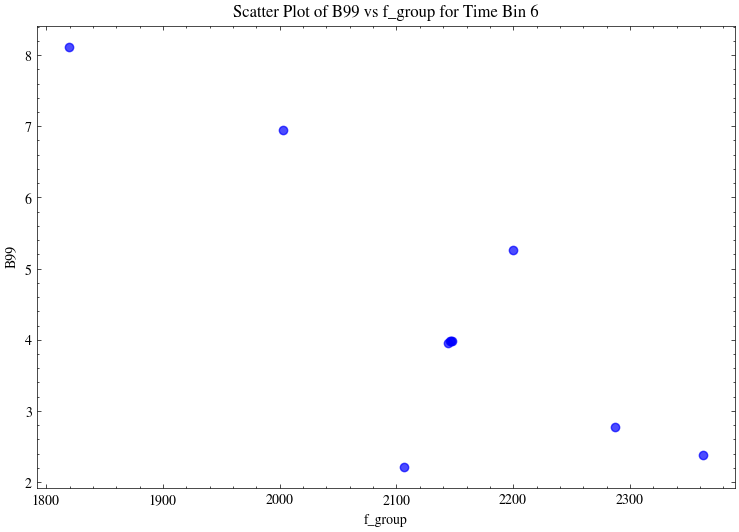

In [ ]:
plt.figure(figsize=(9, 6))
plt.scatter(results_touse_6s['f_group'], results_touse_6s['B99'], c='blue', alpha=0.7)
plt.xlabel('f_group')
plt.ylabel('B99')
plt.title('Scatter Plot of B99 vs f_group for Time Bin 6')
plt.show()